<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Line Charts**


Estimated time needed: **30** minutes


In this lab, you will focus on using line charts to analyze trends over time and across different categories in a dataset.



## Objectives


In this lab you will perform the following:


- Track trends in compensation across age groups and specific age ranges.

- Analyze job satisfaction trends based on experience level.

- Explore and interpret line charts to identify patterns and trends.


## Setup: Working with the Database
**Install the needed libraries**


In [1]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')

In [2]:
# The original `!pip install matplotlib` magic command only runs in Jupyter
# environments. It is kept below as a comment; matplotlib is installed by
# the installer in the cell above so it also works in plain VS Code.
# !pip install matplotlib

**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



#### Step 1: Download the dataset


In [3]:
# The original `!wget` magic command only runs in Jupyter/Linux environments.
# It is kept below as a comment. Use urllib instead so it works in plain VS Code.
# !wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
import os
import urllib.request
import urllib.error

csv_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
csv_file = 'survey-data.csv'
if not (os.path.exists(csv_file) and os.path.getsize(csv_file) > 0):
    print('Downloading survey-data.csv ...')
    urllib.request.urlretrieve(csv_url, csv_file)
print('CSV ready at:', os.path.abspath(csv_file))

CSV ready at: c:\Users\Jerome\github-jtgreta\ibm-data-analyst\09-ibm-data-analyst-capstone-project\survey-data.csv


#### Step 2: Import necessary libraries and load the dataset


In [4]:
import pandas as pd
import matplotlib.pyplot as plt


#### Load the data


In [5]:
# Load the data (cached locally so the notebook still runs when the network is down)
import os
import urllib.request
import urllib.error

data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
local_file = 'survey-data.csv'

def load_dataset(url, local_path, retries=3):
    if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
        try:
            return pd.read_csv(local_path)
        except Exception:
            pass
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            urllib.request.urlretrieve(url, local_path)
            return pd.read_csv(local_path)
        except (urllib.error.URLError, OSError) as e:
            last_err = e
            print(f"Download attempt {attempt}/{retries} failed: {e}")
    raise RuntimeError(
        "Could not download the dataset.\n"
        f"URL: {url}\nLast error: {last_err}\n"
        "Check your internet connection / VPN / proxy, or place a copy of the "
        f"CSV named '{local_path}' next to this notebook."
    )

df = load_dataset(data_url, local_file)

#### Display the first few rows to understand the structure of the data


In [6]:
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Trends in Compensation Over Age Groups


##### 1. Line Chart of Median `ConvertedCompYearly` by Age Group


- Track how the median yearly compensation (ConvertedCompYearly) changes across different age groups.

- Use a line chart to visualize these trends.


Age
18-24 years old        25000.0
25-34 years old        59825.0
35-44 years old        84796.0
45-54 years old        99099.0
55-64 years old       109691.0
65 years or older     106000.0
Prefer not to say     140000.0
Under 18 years old      7626.5
Name: ConvertedCompYearly, dtype: float64


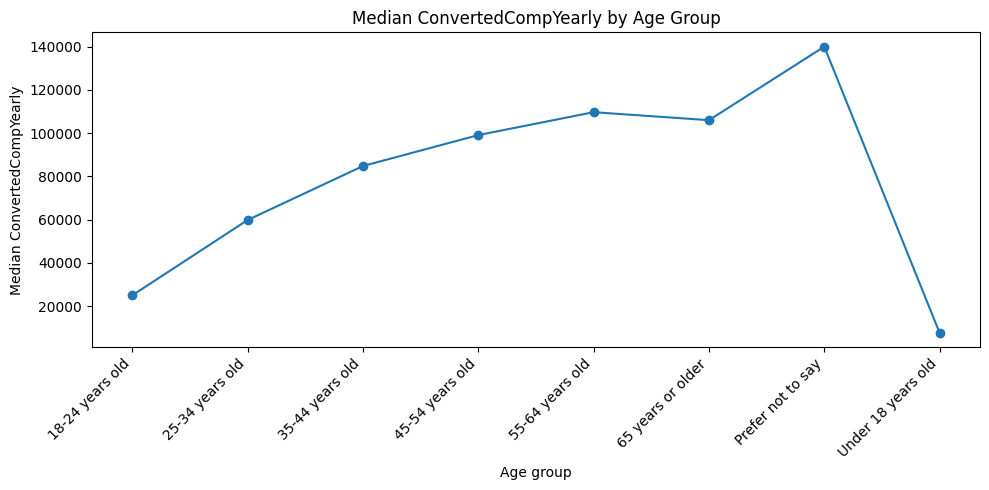

In [7]:
## Write your code here
# Line chart of median ConvertedCompYearly by Age group
median_comp = df.groupby('Age')['ConvertedCompYearly'].median()
print(median_comp)

plt.figure(figsize=(10, 5))
median_comp.plot(kind='line', marker='o')
plt.title('Median ConvertedCompYearly by Age Group')
plt.xlabel('Age group')
plt.ylabel('Median ConvertedCompYearly')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##### 2. Line Chart of Median `ConvertedCompYearly` for Ages 25 to 45


For a closer look, plot a line chart focusing on the median compensation for respondents between ages 25 and 45.


Age
25-34 years old    59825.0
35-44 years old    84796.0
Name: ConvertedCompYearly, dtype: float64


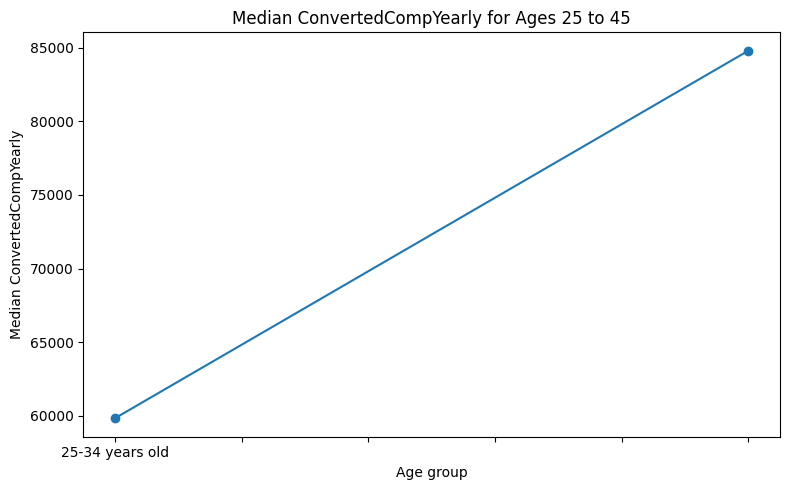

In [8]:
## Write your code here
# Line chart of median ConvertedCompYearly for ages 25 to 45
age_groups = ['25-34 years old', '35-44 years old']
subset = df[df['Age'].isin(age_groups)]
median_comp = subset.groupby('Age')['ConvertedCompYearly'].median()
print(median_comp)

plt.figure(figsize=(8, 5))
median_comp.plot(kind='line', marker='o')
plt.title('Median ConvertedCompYearly for Ages 25 to 45')
plt.xlabel('Age group')
plt.ylabel('Median ConvertedCompYearly')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Task 2: Trends in Job Satisfaction by Experience Level



##### 1. Line Chart of Job Satisfaction (`JobSatPoints_6`) by Experience Level



- Use a column that approximates experience level to analyze how job satisfaction changes with experience.

- If needed, substitute an available experience-related column for `Experience`.


WorkExp
0.0     5.0
1.0    10.0
2.0    15.0
3.0    20.0
4.0    20.0
5.0    20.0
6.0    20.0
7.0    20.0
8.0    20.0
9.0    20.0
Name: JobSatPoints_6, dtype: float64


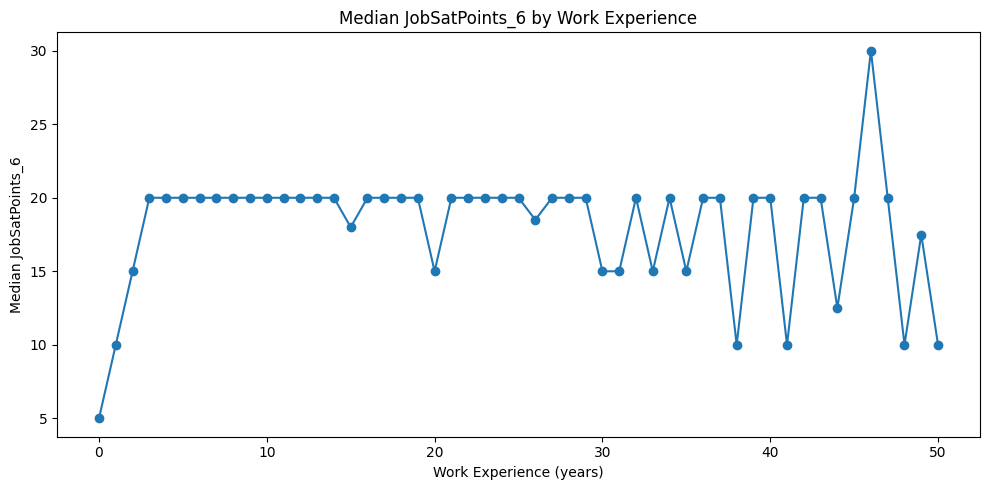

In [9]:
## Write your code here
# Line chart of JobSatPoints_6 by experience level (WorkExp)
exp_sat = df.groupby('WorkExp')['JobSatPoints_6'].median().sort_index()
print(exp_sat.head(10))

plt.figure(figsize=(10, 5))
exp_sat.plot(kind='line', marker='o')
plt.title('Median JobSatPoints_6 by Work Experience')
plt.xlabel('Work Experience (years)')
plt.ylabel('Median JobSatPoints_6')
plt.tight_layout()
plt.show()

### Task 3: Trends in Job Satisfaction and Compensation by Experience


##### 1.Line Chart of Median ConvertedCompYearly Over Experience Level

- This line chart will track how median compensation (`ConvertedCompYearly`) changes with increasing experience.

- Use a column such as `WorkExp` or another relevant experience-related column.


WorkExp
0.0    13306.0
1.0    20077.0
2.0    27968.5
3.0    34896.0
4.0    42962.0
5.0    51624.0
6.0    57140.0
7.0    64444.0
8.0    69814.0
9.0    73932.0
Name: ConvertedCompYearly, dtype: float64


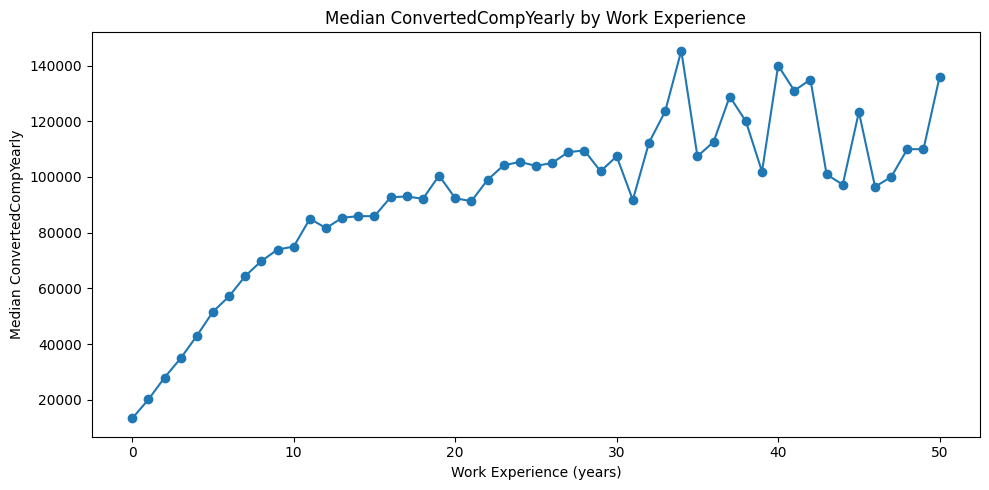

In [10]:
## Write your code here
# Line chart of median ConvertedCompYearly over experience level (WorkExp)
exp_comp = df.groupby('WorkExp')['ConvertedCompYearly'].median().sort_index()
print(exp_comp.head(10))

plt.figure(figsize=(10, 5))
exp_comp.plot(kind='line', marker='o')
plt.title('Median ConvertedCompYearly by Work Experience')
plt.xlabel('Work Experience (years)')
plt.ylabel('Median ConvertedCompYearly')
plt.tight_layout()
plt.show()

##### 2.Line Chart of Job Satisfaction (`JobSatPoints_6`) Across Experience Levels

- Create a line chart to explore trends in job satisfaction (`JobSatPoints_6`) based on experience level.

- This chart will provide insight into how satisfaction correlates with experience over time


WorkExp
0.0     5.0
1.0    10.0
2.0    15.0
3.0    20.0
4.0    20.0
5.0    20.0
6.0    20.0
7.0    20.0
8.0    20.0
9.0    20.0
Name: JobSatPoints_6, dtype: float64


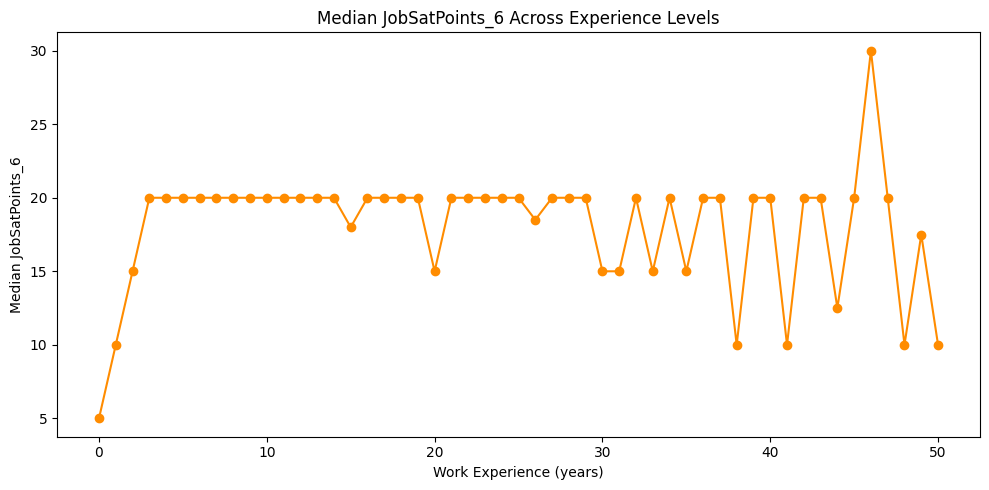

In [ ]:
    ## Write your code here
    # Line chart of JobSatPoints_6 across experience levels (WorkExp)
    exp_sat = df.groupby('WorkExp')['JobSatPoints_6'].median().sort_index()
    print(exp_sat.head(10))

    plt.figure(figsize=(10, 5))
    exp_sat.plot(kind='line', marker='o', color='darkorange')
    plt.title('Median JobSatPoints_6 Across Experience Levels')
    plt.xlabel('Work Experience (years)')
    plt.ylabel('Median JobSatPoints_6')
    plt.tight_layout()
    plt.show()

#### Final Step: Review


In this lab, you focused on analyzing trends in compensation and job satisfaction, specifically exploring how these metrics change with age and experience levels using line charts.


### Summary


In this lab, you explored essential data visualization techniques with a focus on analyzing trends using line charts. You learned to:

- Visualize the distribution of compensation across age groups to understand salary trends.

- Track changes in median compensation over various experience levels, identifying how earnings progress with experience.

- Examine trends in job satisfaction by experience, revealing how satisfaction varies throughout a developer's career.

These analyses allow for a deeper understanding of how factors like age and experience influence job satisfaction and compensation. By using line charts, you gained insights into continuous data patterns, which are invaluable for interpreting professional trends in the developer community.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
